# HW2 — 02: Fine-tune a pretrained audio model

使用 **PANNs Cnn6**：它已在 AudioSet 上学习声音表示，我们再用六类 ESC-50 录音微调后面的层。

**Run notebook 01 first, then Run All here.** This notebook actually trains; all outputs below come from executed cells. CUDA/MPS is used when available, otherwise CPU. GPU runs can vary slightly across platforms.

We use the original AudioSet checkpoint, not a checkpoint already fine-tuned on ESC-50. This controlled homework comparison uses identical train/validation/test clips, but the pretrained model has additional external training data and a different architecture; it does not isolate the causal effect of pretraining. We have not independently audited all upstream pretraining data for overlap.

Sources: [PANNs official implementation](https://github.com/qiuqiangkong/audioset_tagging_cnn), [paper](https://arxiv.org/abs/1912.10211), [official weights](https://zenodo.org/records/3987831). MIT code license: `third_party/PANNs-LICENSE`.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
ROOT = next((p for p in [ROOT, *ROOT.parents]
             if (p / "training/model.py").is_file() and (p / "frontend/package.json").is_file()), ROOT)
assert (ROOT / "training").exists(), "Open this notebook from the sound-detective repository."
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Repository:", ROOT.name)

Repository: sound-detective


## 1. Architecture and verified pretrained weights
Adapted Cnn6 implementation is shown below. The original checkpoint is verified against its published MD5 checksum before loading.

In [2]:
"""Partial fine-tuning of AudioSet-pretrained Cnn6; mirrored in notebook 02."""
import copy
import hashlib
import json
import random
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
from training.features import CLASSES, LABELS
"""PANNs Cnn6 adapted from qiuqiangkong/audioset_tagging_cnn (MIT).
Upstream revision d2f4b8c18eab44737fcc0de1248ae21eb43f6aa4.
See third_party/PANNs-LICENSE. Original AudioSet weights: Zenodo 3987831.
Changes: six-way logits; explicit frozen prefix and trainable final blocks.
"""
import hashlib
from pathlib import Path
from urllib.request import urlopen
import librosa
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchlibrosa.stft import Spectrogram, LogmelFilterBank

PRETRAIN_URL = 'https://zenodo.org/records/3987831/files/Cnn6_mAP%3D0.343.pth?download=1'
PRETRAIN_MD5 = 'e25e26b84585b14c7754c91e48efc9be'
PRETRAIN_VERSION = 'panns-cnn6-audioset-32k-v1'
ROOT = Path.cwd()

class ConvBlock5x5(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 5, padding=2, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        return F.avg_pool2d(F.relu_(self.bn1(self.conv1(x))), (2, 2))

class Cnn6Transfer(nn.Module):
    def __init__(self):
        super().__init__()
        self.spectrogram_extractor = Spectrogram(n_fft=1024, hop_length=320,
            win_length=1024, window='hann', center=True, pad_mode='reflect', freeze_parameters=True)
        self.logmel_extractor = LogmelFilterBank(sr=32000, n_fft=1024,
            n_mels=64, fmin=50, fmax=14000, ref=1.0, amin=1e-10, top_db=None, freeze_parameters=True)
        self.bn0 = nn.BatchNorm2d(64)
        self.conv_block1 = ConvBlock5x5(1, 64)
        self.conv_block2 = ConvBlock5x5(64, 128)
        self.conv_block3 = ConvBlock5x5(128, 256)
        self.conv_block4 = ConvBlock5x5(256, 512)
        self.fc1 = nn.Linear(512, 512)
        self.fc_audioset = nn.Linear(512, 6)

    def freeze_prefix(self):
        for name, parameter in self.named_parameters():
            parameter.requires_grad = name.startswith(('conv_block4.', 'fc1.', 'fc_audioset.'))
        # Keep ALL BN running statistics fixed; six-class data is too small.
        self.train(self.training)

    def train(self, mode=True):
        super().train(mode)
        for module in self.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
        return self

    def prefix(self, waveform):
        x = self.logmel_extractor(self.spectrogram_extractor(waveform))
        x = self.bn0(x.transpose(1, 3)).transpose(1, 3)
        for block in [self.conv_block1, self.conv_block2, self.conv_block3]:
            x = block(x)
        return x

    def tail(self, x):
        x = self.conv_block4(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = x.mean(dim=3)
        x = x.amax(dim=2) + x.mean(dim=2)
        x = F.dropout(x, p=0.5, training=self.training)
        x = F.relu_(self.fc1(x))
        x = F.dropout(x, p=0.5, training=self.training)
        return self.fc_audioset(x)

    def forward(self, waveform):
        return self.tail(self.prefix(waveform))

def waveform32k(audio, sr):
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if audio.ndim != 1 or not np.isfinite(audio).all():
        raise ValueError('Audio must contain finite samples.')
    if not 0.25 <= len(audio) / sr <= 10:
        raise ValueError('Use a WAV recording between 0.25 and 10 seconds.')
    if np.max(np.abs(audio)) < 1e-6:
        raise ValueError('This recording is silent. Choose an audible recording.')
    audio = librosa.resample(audio, orig_sr=sr, target_sr=32000)
    return librosa.util.fix_length(audio, size=160000)

def load_audioset():
    path = ROOT / 'data/cache/Cnn6_mAP=0.343.pth'
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urlopen(PRETRAIN_URL, timeout=120) as response:
            content = response.read()
        if hashlib.md5(content).hexdigest() != PRETRAIN_MD5:
            raise ValueError('Downloaded PANNs checkpoint failed checksum verification.')
        path.write_bytes(content)
    if hashlib.md5(path.read_bytes()).hexdigest() != PRETRAIN_MD5:
        raise ValueError('PANNs checkpoint checksum mismatch.')
    model = Cnn6Transfer()
    state = torch.load(path, map_location='cpu', weights_only=True)['model']
    # Reinitialize only the original 527-class AudioSet output layer.
    state = {k: v for k, v in state.items() if not k.startswith('fc_audioset.')}
    missing, unexpected = model.load_state_dict(state, strict=False)
    assert set(missing) == {'fc_audioset.weight', 'fc_audioset.bias'} and not unexpected
    model.freeze_prefix()
    return model

from training.train import scores

ROOT = Path.cwd()
OUT = ROOT / 'training/results'
MODEL_DIR = ROOT / 'backend/model'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / 'data/cache').mkdir(parents=True, exist_ok=True)
SEED = 7400

In [3]:
# Download the 240 selected recordings only if they are not already present.
from training.prepare import main as prepare_data
if not (ROOT / 'data/raw/manifest.json').exists():
    prepare_data()

## 2. Load AudioSet weights and freeze layers
The original 527-way output is replaced with a randomly initialized six-way head. Conv blocks 1–3 and all BN running statistics stay frozen. Block 4 and the pretrained fc1 are genuinely updated, in addition to the new head. This is **partial fine-tuning**, not only a frozen embedding classifier.

In [4]:
torch.set_num_threads(2)
torch.use_deterministic_algorithms(False)  # MPS kernels can vary across systems.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
model = load_audioset().to(device)
initial_tail = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k.startswith(('conv_block4.', 'fc1.'))}
rows = json.loads((ROOT / 'data/raw/manifest.json').read_text())
y = torch.tensor([CLASSES.index(r['category']) for r in rows])
masks = {name: np.array([int(r['fold']) in folds for r in rows]) for name, folds in [('train', [1, 2, 3]), ('validation', [4]), ('test', [5])]}
source_sets = [{r['src_file'] for r, keep in zip(rows, masks[name]) if keep} for name in masks]
assert not (source_sets[0] & source_sets[1] or source_sets[0] & source_sets[2] or source_sets[1] & source_sets[2])
print('Device:', device, '| fine-tuned parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad), flush=True)

Device: mps | fine-tuned parameters: 3543558


## 3. Cache the frozen prefix
Caching the first three frozen blocks avoids repeating unchanged computation. No dataset statistics are fitted here. The same waveform preprocessing is used at inference: 32 kHz, 5 seconds, 64 log-mel bands.

In [5]:
# The first three blocks and their BN statistics never change. Cache them once.
# Test representations are extracted independently; no fitting or statistics use them.
cache = ROOT / 'data/cache/panns-prefix.pt'
signature = hashlib.sha256(json.dumps(rows, sort_keys=True).encode()).hexdigest() + PRETRAIN_MD5
if cache.exists():
    saved = torch.load(cache, map_location='cpu', weights_only=True)
    assert saved['signature'] == signature and saved['version'] == PRETRAIN_VERSION
    features = saved['features']
else:
    batches = []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(rows), 8):
            waves = np.stack([waveform32k(*sf.read(ROOT / 'data/raw/audio' / r['filename'])) for r in rows[start:start + 8]])
            batches.append(model.prefix(torch.from_numpy(waves).to(device)).cpu())
            print(f'Frozen-prefix extraction: {min(start + 8, len(rows))}/{len(rows)}', flush=True)
    features = torch.cat(batches)
    torch.save({'features': features, 'signature': signature, 'version': PRETRAIN_VERSION}, cache)
xs = {name: features[mask] for name, mask in masks.items()}
ys = {name: y[mask] for name, mask in masks.items()}

## 4. Fine-tune pretrained layers
Fixed before viewing this model’s test result: AdamW, backbone LR 1e-4, head LR 1e-3, batch 8, max 20 epochs, patience 5. The explicit loop below computes logits, cross-entropy, gradients and parameter updates. Checkpoint selection uses validation loss only.

In [6]:
# Fixed in advance: one schedule, not selected by observed test performance.
optimizer = torch.optim.AdamW([
    {'params': list(model.conv_block4.parameters()) + list(model.fc1.parameters()), 'lr': 1e-4},
    {'params': model.fc_audioset.parameters(), 'lr': 1e-3},
], weight_decay=0.01)
criterion = torch.nn.CrossEntropyLoss()
history, best, best_loss, stale = [], None, float('inf'), 0
def evaluate(name):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model.tail(batch.to(device)).cpu() for batch in xs[name].split(8)])
    return logits, float(criterion(logits, ys[name]))
for epoch in range(1, 21):
    model.train()  # Dropout on; BN running statistics remain frozen.
    for index in torch.randperm(len(xs['train'])).split(8):
        optimizer.zero_grad()
        logits = model.tail(xs['train'][index].to(device))
        loss = criterion(logits, ys['train'][index].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 5.0)
        optimizer.step()
    entry = {'epoch': epoch}
    for name in ['train', 'validation']:
        logits, loss = evaluate(name)
        entry[f'{name}_loss'] = loss
        entry[f'{name}_accuracy'] = float((logits.argmax(1) == ys[name]).float().mean())
    history.append(entry)
    print(entry, flush=True)
    if entry['validation_loss'] < best_loss - 1e-6:
        best_loss, stale = entry['validation_loss'], 0
        best = {'epoch': epoch, 'state_dict': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    else:
        stale += 1
    if stale >= 5:
        break

{'epoch': 1, 'train_loss': 1.265852451324463, 'train_accuracy': 0.7430555820465088, 'validation_loss': 1.2879756689071655, 'validation_accuracy': 0.6875}


{'epoch': 2, 'train_loss': 0.8742870688438416, 'train_accuracy': 0.8472222089767456, 'validation_loss': 0.9001710414886475, 'validation_accuracy': 0.8541666865348816}


{'epoch': 3, 'train_loss': 0.6132720708847046, 'train_accuracy': 0.9583333134651184, 'validation_loss': 0.6518681049346924, 'validation_accuracy': 0.9583333134651184}


{'epoch': 4, 'train_loss': 0.44710010290145874, 'train_accuracy': 0.9652777910232544, 'validation_loss': 0.48607519268989563, 'validation_accuracy': 0.9375}


{'epoch': 5, 'train_loss': 0.3427741825580597, 'train_accuracy': 0.9722222089767456, 'validation_loss': 0.3799115717411041, 'validation_accuracy': 0.9583333134651184}


...

{'epoch': 16, 'train_loss': 0.05971832573413849, 'train_accuracy': 1.0, 'validation_loss': 0.09373229742050171, 'validation_accuracy': 1.0}


{'epoch': 17, 'train_loss': 0.054241668432950974, 'train_accuracy': 1.0, 'validation_loss': 0.08654379099607468, 'validation_accuracy': 1.0}


{'epoch': 18, 'train_loss': 0.045879315584897995, 'train_accuracy': 1.0, 'validation_loss': 0.08125390857458115, 'validation_accuracy': 1.0}


{'epoch': 19, 'train_loss': 0.041599079966545105, 'train_accuracy': 1.0, 'validation_loss': 0.07524427771568298, 'validation_accuracy': 1.0}


{'epoch': 20, 'train_loss': 0.04001860320568085, 'train_accuracy': 1.0, 'validation_loss': 0.07204806059598923, 'validation_accuracy': 1.0}


## 5. Restore and evaluate
Restore the best validation checkpoint. Assertions check that the pretrained convolution and fc1 weights changed. Now evaluate the same held-out 48 clips used for the MLP.

In [7]:
# Restore validation-selected weights BEFORE evaluating the untouched test labels.
model.load_state_dict(best['state_dict'])
report = {'model': 'PANNs Cnn6 (AudioSet), partially fine-tuned', 'classes': CLASSES,
    'labels': LABELS, 'seed': SEED, 'device': str(device), 'feature_version': PRETRAIN_VERSION,
    'pretrained_source': PRETRAIN_URL, 'pretrained_md5': PRETRAIN_MD5,
    'trainable_layers': ['conv_block4', 'fc1', 'fc_audioset (new six-class head)'],
    'frozen': 'spectrogram/logmel, bn0, conv blocks 1–3, all BN running statistics',
    'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
    'config': {'epoch': best['epoch'], 'max_epochs': 20, 'patience': 5, 'batch_size': 8,
               'backbone_lr': 1e-4, 'head_lr': 1e-3, 'weight_decay': 0.01, 'optimizer': 'AdamW'},
    'counts': {name: int(mask.sum()) for name, mask in masks.items()}, 'history': history,
    'selection': 'One fixed schedule; minimum fold-4 validation loss; fold 5 excluded from selection.',
    'metrics': {}, 'test_predictions': [],
    'pretrained_weight_changes': {k: float((best['state_dict'][k] - v).abs().max()) for k, v in initial_tail.items() if v.is_floating_point()}}
assert report['pretrained_weight_changes']['conv_block4.conv1.weight'] > 0
assert report['pretrained_weight_changes']['fc1.weight'] > 0
for name in masks:
    logits, loss = evaluate(name)
    report['metrics'][name] = {**scores(ys[name], logits.argmax(1)), 'loss': loss}
    if name == 'test':
        for row, probs in zip([r for r in rows if int(r['fold']) == 5], logits.softmax(1).tolist()):
            report['test_predictions'].append({'filename': row['filename'], 'actual': row['category'],
                'predicted': CLASSES[int(np.argmax(probs))], 'probabilities': probs})

## 6. Save the fine-tuned checkpoint
Save all weights, metrics, per-clip predictions, weight-change evidence and learning curves. The saved model can run offline without downloading the original AudioSet checkpoint.

In [8]:
torch.save({'state_dict': best['state_dict'], 'classes': CLASSES,
            'feature_version': PRETRAIN_VERSION}, MODEL_DIR / 'sound-panns.pt')
(OUT / 'pretrained-metrics.json').write_text(json.dumps(report, indent=2) + '\n')
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ['train', 'validation']:
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot([h['epoch'] for h in history], [h[f'{name}_{metric}'] for h in history], label=name)
        ax.set(xlabel='Epoch', ylabel=metric)
for ax in axes:
    ax.axvline(best['epoch'], ls='--', color='gray', label='selected checkpoint'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'pretrained-learning-curves.png', dpi=160); plt.close(fig)
print(json.dumps(report['metrics'], indent=2))

{
  "train": {
    "accuracy": 1.0,
    "macro_f1": 1.0,
    "confusion_matrix": [
      [
        24,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        24,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        24,
        0,
        0,
        0
      ],
      [
        0,
        0,
        0,
        24,
        0,
        0
      ],
      [
        0,
        0,
        0,
        0,
        24,
        0
      ],
      [
        0,
        0,
        0,
        0,
        0,
        24
      ]
    ],
    "loss": 0.04001860320568085
  },
  "validation": {
    "accuracy": 1.0,
    "macro_f1": 1.0,
    "confusion_matrix": [
      [
        8,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        8,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        8,
        0,
        0,
        0
      ],
      [
        0,
        0,
        0,
   

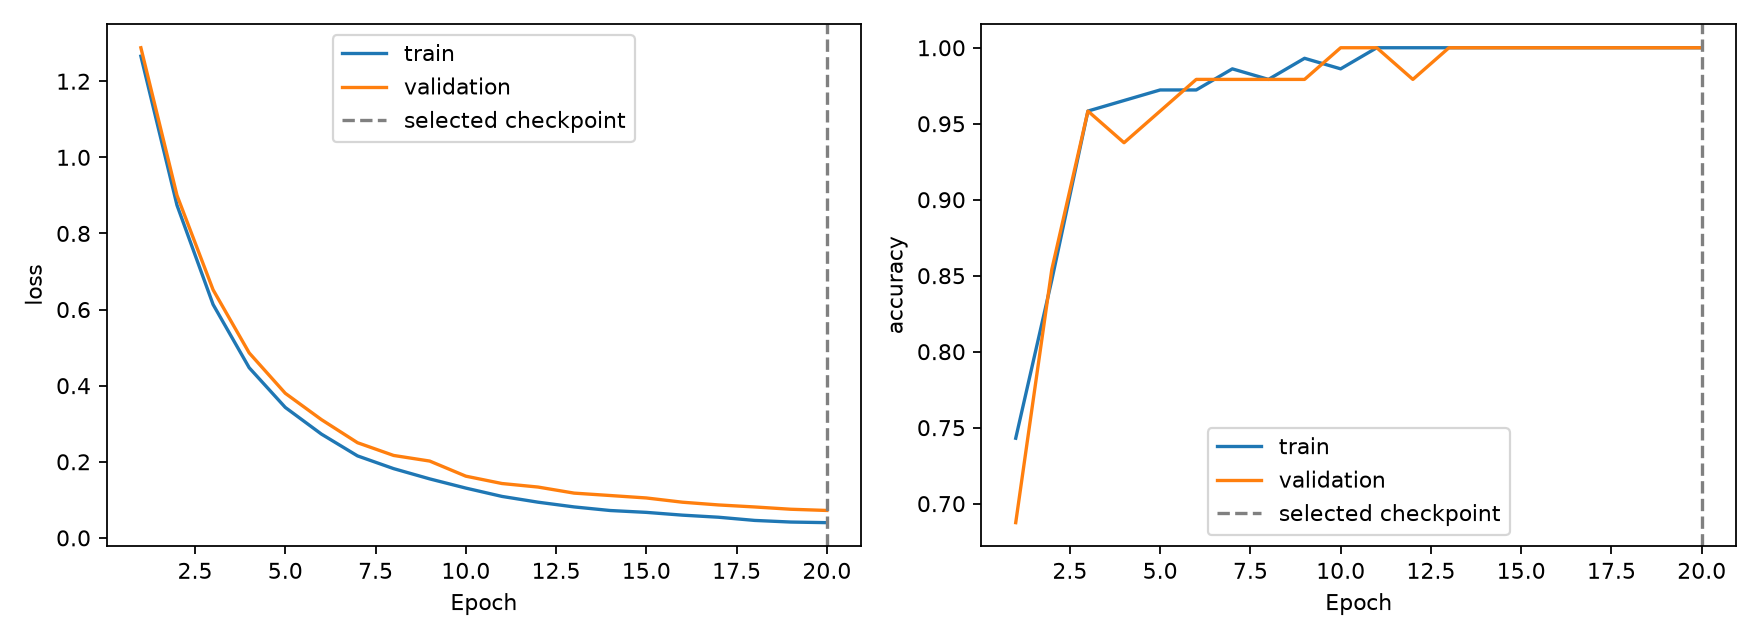

In [9]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'pretrained-learning-curves.png')))

## 7. Compare models
Compare identical test clips. Do not assume a pretrained model must win. Interpret any difference alongside external pretraining, capacity, feature choice, and the small 48-clip test set.

Logistic regression        accuracy=75.00%, macro F1=0.7509
MLP from scratch           accuracy=85.42%, macro F1=0.8583
Fine-tuned PANNs Cnn6      accuracy=95.83%, macro F1=0.9566


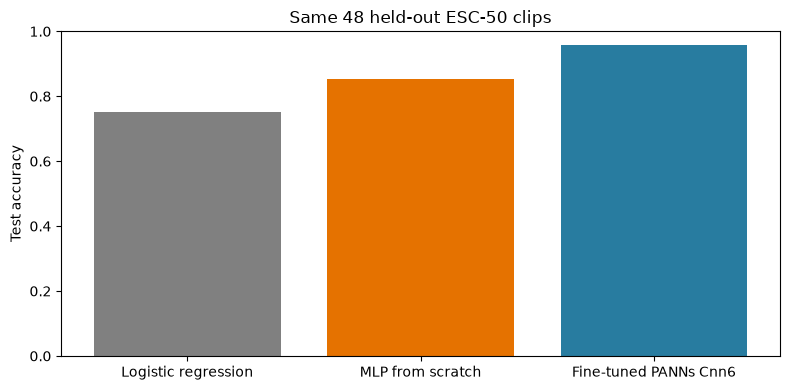

In [10]:
simple = json.loads((OUT / 'metrics.json').read_text())
comparison = {
    'Logistic regression': simple['baseline']['test'],
    'MLP from scratch': simple['mlp']['test'],
    'Fine-tuned PANNs Cnn6': report['metrics']['test'],
}
for name, metrics in comparison.items():
    print(f"{name:26s} accuracy={metrics['accuracy']:.2%}, macro F1={metrics['macro_f1']:.4f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(comparison), [m['accuracy'] for m in comparison.values()], color=['gray', '#e57200', '#287ca0'])
ax.set(ylim=(0, 1), ylabel='Test accuracy', title='Same 48 held-out ESC-50 clips')
fig.tight_layout()
fig.savefig(OUT / 'model-comparison.png', dpi=160)
plt.show()

## Explain it yourself
预训练和微调有什么区别？哪些层更新了？冻结的 BN 为什么不能继续更新均值和方差？为什么两个模型不能仅凭准确率差就断言预训练一定更好？

The app can switch between both saved models. Probabilities from either model are not calibrated certainty.